# Imports

In [8]:
# ! pip install mlflow

In [1]:

# for authentication
from azure.identity import DefaultAzureCredential
from azure.ai.ml import MLClient

# sklearn and other modules
import os
import mlflow
import pickle
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score, precision_score
from sklearn.ensemble import RandomForestClassifier

/anaconda/envs/azureml_py310_sdkv2/lib/python3.10/site-packages/mlflow/__init__.py:41: UserWarning: Versions of mlflow (3.16.0) and child packages mlflow-skinny (3.15.0) are different. This may lead to unexpected behavior. Please install the same version of all MLflow packages.
  mlflow.mismatch._check_version_mismatch()
/anaconda/envs/azureml_py310_sdkv2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Authenticate

In [2]:
credential = DefaultAzureCredential()

ml_client = MLClient(
    credential=credential,
    # subscription_id="[REDACTED_SUBSCRIPTION_ID]", # your subscription id
    # workspace_name="[REDACTED_WORKSPACE]", # your workspace name
    # resource_group_name="[REDACTED_RESOURCE_GROUP]" # your resource group name
)

# Set up mlflow experiment

More about MLFlow within Azure ML: https://learn.microsoft.com/en-us/azure/machine-learning/concept-mlflow?view=azureml-api-2

All jobs will be grouped under this experiment

In [3]:
mlflow.set_experiment("mini-project-2-telecom-churn")

2026/10/17 19:04:38 INFO mlflow.tracking.fluent: Experiment with name 'mini-project-2-telecom-churn' does not exist. Creating a new experiment.


<Experiment: artifact_location='', creation_time=1792263879201, effective_trace_archival_retention=None, experiment_id='2bb61b77-fbe1-4042-9a98-a6a5004543d0', last_update_time=None, lifecycle_stage='active', name='mini-project-2-telecom-churn', tags={}, trace_location=None, workspace='default'>

# Data Pre-Processing Steps

In [4]:
with mlflow.start_run(run_name="data preparation run") as run:
    # consume the previously created data asset -> we will consume version 2
    data_asset = ml_client.data.get(name="telecom_churn_dataset_mlops", version="v2")

    # load the data as a pandas dataframe
    df = pd.read_csv(data_asset.path)

    # remove duplicate records
    df = df.drop_duplicates()

    # create a new feature - average daytime minutes per call
    df["AvgDayMinsPerCall"] = df["DayMins"] / df["DayCalls"].replace(0, 1)

    # perform train-test split
    test_size = 0.3
    target_column_name = 'Churn'

    X_train, X_test, Y_train, Y_test = train_test_split(
        df[df.columns.difference([target_column_name]).values],
        df[target_column_name],
        stratify=df[target_column_name],
        test_size=test_size,
        random_state=123456
    )

    # log metrics and parameters with mlflow
    mlflow.log_metric("Test Set Size", test_size)
    mlflow.log_param("Target Label Column Name", target_column_name)
    mlflow.log_param("Training Data Shape", str(X_train.shape))
    mlflow.log_param("Test Data Shape", str(X_test.shape))

    # additional logging for Mini Project 2
    mlflow.log_param("Preprocessing Transformations", "Removed duplicate records; handled zero daytime calls")
    mlflow.log_param("New Feature Added", "AvgDayMinsPerCall")
    mlflow.log_param("Test Size Proportion", test_size)

    print("Training Data Shape:", X_train.shape)
    print("Test Data Shape:", X_test.shape)
    print("New Feature Added:", "AvgDayMinsPerCall")

Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented


Training Data Shape: (2333, 11)
Test Data Shape: (1000, 11)
New Feature Added: AvgDayMinsPerCall
🏃 View run data preparation run at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0/runs/a685b78d-9bc2-452f-85e7-8a8bca910e57
🧪 View experiment at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0


# Classification Model Development

- `mlflow` supports autologging for popular libraries like sklearn, pytorch, etc. which helps us log metrics, model parameters, model artifact files, etc. with minimal effort. 
- If we do not wish to use autologging, we can also manually log these metrics
- We can also combine autologging with manual logging to capture additional metrics not covered by autologging.


More about mlflow logging:
- https://learn.microsoft.com/en-us/azure/machine-learning/how-to-use-mlflow-cli-runs?view=azureml-api-2&tabs=interactive%2Ccli
- https://learn.microsoft.com/en-us/azure/machine-learning/how-to-log-view-metrics?view=azureml-api-2&tabs=interactive
- https://mlflow.org/docs/latest/tracking/autolog.html

##### Autologging with mlflow


2026/10/17 19:22:04 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "/anaconda/envs/azureml_py310_sdkv2/lib/python3.10/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/17 19:22:05 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "/anaconda/envs/azureml_py310_sdkv2

Test Accuracy: 0.931
Test F1 Score: 0.7250996015936255
Test Precision: 0.8584905660377359
🏃 View run model training and evaluation run at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0/runs/b1743f0c-3712-4601-a982-36d94026480c
🧪 View experiment at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0


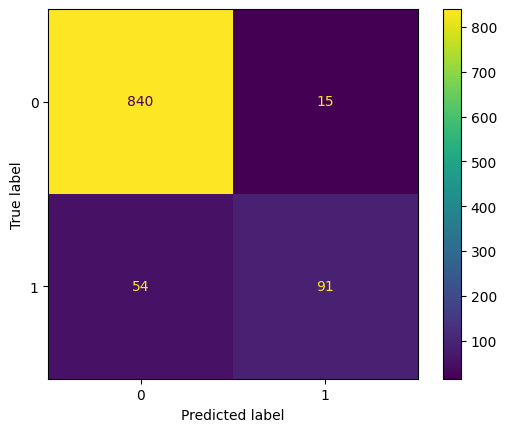

In [5]:
with mlflow.start_run(run_name="model training and evaluation run") as run:

    # this will help us use mlflow for automatic logging
    mlflow.sklearn.autolog()

    # train a random forest classification model - these model parameters will be logged
    n_estimators = 100
    max_depth = 10
    random_state = 123456

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        random_state=random_state
    )

    # the model artifact (pickle file) will be automatically logged
    model.fit(
        X_train, Y_train
    )

    # calculate accuracy - mlflow will automatically log this
    acc = model.score(X_test, Y_test)
    print("Test Accuracy:", acc)

    # calculate additional metrics required for Mini Project 2
    predictions = model.predict(X_test)

    f1 = f1_score(Y_test, predictions)
    precision = precision_score(Y_test, predictions)

    mlflow.log_metric("Test F1 Score", f1)
    mlflow.log_metric("Test Precision", precision)

    print("Test F1 Score:", f1)
    print("Test Precision:", precision)

    # log plots for model performance using mlflow
    cm = confusion_matrix(Y_test, predictions, labels=model.classes_)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )
    mlflow.log_figure(disp.plot().figure_, "test_set_confusion_matrix.png") # log the test set confusion matrix

# Registering a Model

#### Get the `experiment id` for the experiment we just ran

In [33]:
experiment_id = mlflow.get_experiment_by_name("mini-project-2-telecom-churn").experiment_id
print(experiment_id)

2bb61b77-fbe1-4042-9a98-a6a5004543d0


#### Get all the `run ids` within the experiment

In [34]:
mlflow.search_runs(
    experiment_ids=[experiment_id],
    filter_string="attributes.status='Finished'",
    order_by=["attributes.start_time DESC"]
)

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.Test F1 Score,metrics.Test Precision,metrics.Test Set Size,params.criterion,...,params.Training Data Shape,params.Test Size Proportion,params.Test Data Shape,params.New Feature Added,params.Preprocessing Transformations,tags.estimator_name,tags.estimator_class,tags.mlflow.runName,tags.mlflow.rootRunId,tags.mlflow.user
0,b1743f0c-3712-4601-a982-36d94026480c,2bb61b77-fbe1-4042-9a98-a6a5004543d0,FINISHED,,2026-10-17 19:22:03.158000+00:00,2026-10-17 19:22:09.145000+00:00,0.7251,0.858491,NaN,gini,...,None,None,None,None,None,RandomForestClassifier,sklearn.ensemble._forest.RandomForestClassifier,model training and evaluation run,b1743f0c-3712-4601-a982-36d94026480c,[REDACTED_NAME]
1,a685b78d-9bc2-452f-85e7-8a8bca910e57,2bb61b77-fbe1-4042-9a98-a6a5004543d0,FINISHED,,2026-10-17 19:10:14.262000+00:00,2026-10-17 19:10:22.365000+00:00,NaN,NaN,0.3,None,...,"(2333, 11)",0.3,"(1000, 11)",AvgDayMinsPerCall,Removed duplicate records; handled zero daytim...,None,None,data preparation run,a685b78d-9bc2-452f-85e7-8a8bca910e57,[REDACTED_NAME]


#### Register Model

In [36]:
# create a new run and save the trained model
with mlflow.start_run(run_name="random forest model registration run") as run:

    run_id = run.info.run_id

    temporary_folder_name = 'temp_data/'
    if not os.path.exists(temporary_folder_name):
        os.mkdir(temporary_folder_name)

    model_pickle_file = temporary_folder_name + 'model.pkl'

    with open(model_pickle_file, 'wb') as f:
        pickle.dump(model, f)

    mlflow.log_artifact(model_pickle_file, "model")

    print("Model Run ID:", run_id)
    print("Model artifact saved successfully.")

Model Run ID: bb196c6d-6527-4555-b7a6-5e8f955ba650
Model artifact saved successfully.
🏃 View run random forest model registration run at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0/runs/bb196c6d-6527-4555-b7a6-5e8f955ba650
🧪 View experiment at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0


#### a.	Programmatically fetch the latest model that was trained by using the experiment name and the experiment id

In [37]:
from azure.ai.ml.entities import Model

run_id = 'b1743f0c-3712-4601-a982-36d94026480c'
run_model = Model(
    path="runs:/"+run_id+"/model/",
    name="telecom-churn-random-forest",
    description="Random Forest classification model for telecom customer churn",
)

ml_client.models.create_or_update(run_model)

Model({'job_name': 'b1743f0c-3712-4601-a982-36d94026480c', 'intellectual_property': None, 'system_metadata': None, 'is_anonymous': False, 'auto_increment_version': False, 'auto_delete_setting': None, 'name': 'telecom-churn-random-forest', 'description': 'Random Forest classification model for telecom customer churn', 'tags': {}, 'properties': {}, 'print_as_yaml': False, 'id': '/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/models/telecom-churn-random-forest/versions/2', 'Resource__source_path': '', 'base_path': '/mnt/batch/tasks/shared/LS_root/mounts/clusters/amlcomputeops0001/code/Users/nickdhollman/Mini Project 2', 'creation_context': <azure.ai.ml.entities._system_data.SystemData object at 0x737422008d60>, 'version': '2', 'latest_version': None, 'path': 'azureml://subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/workspaces/[REDACTED_WORKSPAC

In [40]:
# get experiment id using experiment name
experiment_id = mlflow.get_experiment_by_name("mini-project-2-telecom-churn").experiment_id

# get the latest completed Random Forest training run
client = mlflow.tracking.MlflowClient()

runs = client.search_runs(
    experiment_ids=[experiment_id],
    order_by=["attributes.start_time DESC"]
)

for run in runs:
    if run.data.metrics.get("Test F1 Score") is not None:
        run_id = run.info.run_id
        break
else:
    raise ValueError("No Random Forest training run found.")

print("Experiment ID:", experiment_id)
print("Run ID:", run_id)

Experiment ID: 2bb61b77-fbe1-4042-9a98-a6a5004543d0
Run ID: b1743f0c-3712-4601-a982-36d94026480c


In [41]:
run_model = Model(
    path="runs:/"+run_id+"/model/",
    name="telecom-churn-random-forest",
    description="Random Forest classification model for telecom customer churn",
)

ml_client.models.create_or_update(run_model)

Model({'job_name': 'b1743f0c-3712-4601-a982-36d94026480c', 'intellectual_property': None, 'system_metadata': None, 'is_anonymous': False, 'auto_increment_version': False, 'auto_delete_setting': None, 'name': 'telecom-churn-random-forest', 'description': 'Random Forest classification model for telecom customer churn', 'tags': {}, 'properties': {}, 'print_as_yaml': False, 'id': '/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/models/telecom-churn-random-forest/versions/3', 'Resource__source_path': '', 'base_path': '/mnt/batch/tasks/shared/LS_root/mounts/clusters/amlcomputeops0001/code/Users/nickdhollman/Mini Project 2', 'creation_context': <azure.ai.ml.entities._system_data.SystemData object at 0x73742200e680>, 'version': '3', 'latest_version': None, 'path': 'azureml://subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/workspaces/[REDACTED_WORKSPAC


## Question 4: Random Forest Hyperparameter Optimization

### Grid Search with Cross-Validation

We will use GridSearchCV to optimize the Random Forest classifier by evaluating multiple hyperparameter combinations. The parameters being evaluated include n_estimators, max_depth, min_samples_split, and min_samples_leaf.

Five-fold cross-validation will be used to evaluate each combination, with F1 score as the primary performance metric due to the class imbalance in the churn dataset.

The best-performing model will then be evaluated against the original Random Forest model using the same 70/30 train-test split. The selected model will be registered as a new version in the Azure ML Model Registry.

In [42]:
from sklearn.model_selection import GridSearchCV

# define the Random Forest model
rf = RandomForestClassifier(random_state=123456)

# define hyperparameters to evaluate
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# perform grid search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# fit the grid search using the training data
grid_search.fit(X_train, Y_train)

# retrieve the best model and parameters
optimized_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)

2026/10/17 20:23:55 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '97af0928-f892-4375-a294-baafd7bce55e', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2026/10/17 20:23:56 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "/anaconda/envs/azureml_py310_sdkv2/lib/python3.10/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers 

🏃 View run nice_cassava_1bgpc2jy at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0/runs/97af0928-f892-4375-a294-baafd7bce55e
🧪 View experiment at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0
Best Parameters: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-Validation F1 Score: 0.7521007521065753


In [45]:
# evaluate the optimized Random Forest model
optimized_predictions = optimized_model.predict(X_test)

optimized_accuracy = optimized_model.score(X_test, Y_test)
optimized_f1 = f1_score(Y_test, optimized_predictions)
optimized_precision = precision_score(Y_test, optimized_predictions)

print("Optimized Random Forest Results:")
print("Test Accuracy:", optimized_accuracy)
print("Test F1 Score:", optimized_f1)
print("Test Precision:", optimized_precision)

# evaluate the original Random Forest model
baseline_predictions = model.predict(X_test)

print("\nBaseline Random Forest Results:")
print("Test Accuracy:", model.score(X_test, Y_test))
print("Test F1 Score:", f1_score(Y_test, baseline_predictions))
print("Test Precision:", precision_score(Y_test, baseline_predictions))

Optimized Random Forest Results:
Test Accuracy: 0.937
Test F1 Score: 0.7428571428571429
Test Precision: 0.91

Baseline Random Forest Results:
Test Accuracy: 0.931
Test F1 Score: 0.7250996015936255
Test Precision: 0.8584905660377359



### Logging the Optimized Random Forest Model

The best Random Forest model selected through GridSearchCV will be saved and logged to MLflow. The selected hyperparameters, test accuracy, F1 score, precision, and confusion matrix will be recorded to support model tracking and registration.


Optimized Model Run ID: a1a0f7ca-cb9f-41be-ad8d-e56c875502bd
Optimized model logged successfully.
🏃 View run optimized random forest model at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0/runs/a1a0f7ca-cb9f-41be-ad8d-e56c875502bd
🧪 View experiment at: https://eastus2.api.azureml.ms/mlflow/v2.0/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/#/experiments/2bb61b77-fbe1-4042-9a98-a6a5004543d0


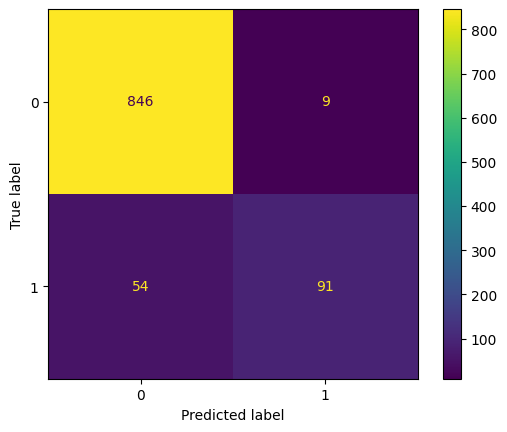

In [46]:
# log the optimized model using mlflow
mlflow.sklearn.autolog(disable=True)

with mlflow.start_run(run_name="optimized random forest model") as run:

    optimized_run_id = run.info.run_id

    # log best hyperparameters
    for param, value in grid_search.best_params_.items():
        mlflow.log_param(param, value)

    mlflow.log_metric("Best CV F1 Score", grid_search.best_score_)
    mlflow.log_metric("Test Accuracy", optimized_accuracy)
    mlflow.log_metric("Test F1 Score", optimized_f1)
    mlflow.log_metric("Test Precision", optimized_precision)

    # save optimized model as a pickle file
    temporary_folder_name = 'temp_data/'
    if not os.path.exists(temporary_folder_name):
        os.mkdir(temporary_folder_name)

    model_pickle_file = temporary_folder_name + 'optimized_model.pkl'

    with open(model_pickle_file, 'wb') as f:
        pickle.dump(optimized_model, f)

    mlflow.log_artifact(model_pickle_file, "model")

    # log test set confusion matrix
    cm = confusion_matrix(
        Y_test,
        optimized_model.predict(X_test),
        labels=optimized_model.classes_
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=optimized_model.classes_
    )

    mlflow.log_figure(
        disp.plot().figure_,
        "test_set_confusion_matrix.png"
    )

    print("Optimized Model Run ID:", optimized_run_id)
    print("Optimized model logged successfully.")

### Registering the Optimized Random Forest Model

The optimized Random Forest model will be registered in the Azure ML Model Registry as a new version of the previously registered model. This allows both the baseline and optimized models to be maintained and compared for future deployment.

In [47]:
from azure.ai.ml.entities import Model

run_model = Model(
    path="runs:/"+optimized_run_id+"/model/",
    name="telecom-churn-random-forest",
    description="Hyperparameter optimized Random Forest model for telecom customer churn",
)

ml_client.models.create_or_update(run_model)

Model({'job_name': 'a1a0f7ca-cb9f-41be-ad8d-e56c875502bd', 'intellectual_property': None, 'system_metadata': None, 'is_anonymous': False, 'auto_increment_version': False, 'auto_delete_setting': None, 'name': 'telecom-churn-random-forest', 'description': 'Hyperparameter optimized Random Forest model for telecom customer churn', 'tags': {}, 'properties': {}, 'print_as_yaml': False, 'id': '/subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/providers/Microsoft.MachineLearningServices/workspaces/[REDACTED_WORKSPACE]/models/telecom-churn-random-forest/versions/4', 'Resource__source_path': '', 'base_path': '/mnt/batch/tasks/shared/LS_root/mounts/clusters/amlcomputeops0001/code/Users/nickdhollman/Mini Project 2', 'creation_context': <azure.ai.ml.entities._system_data.SystemData object at 0x737422020670>, 'version': '4', 'latest_version': None, 'path': 'azureml://subscriptions/[REDACTED_SUBSCRIPTION_ID]/resourceGroups/[REDACTED_RESOURCE_GROUP]/workspaces/[REDACTE